# Bitcoin OTC: how positive ratings accumulated

**Focused question:** did positive ratings become more concentrated on a few users over time, and were users who already had many ratings chosen more often than chance would predict?

The timestamps tell us when a rating was added, not whether it was still meant later. So the network at a date is the recorded history up to that date.

## 1. Results files

Run `python scripts/reproduce.py` from the project folder first. It runs `temporal_analysis.py` and `temporal_sensitivity.py`, whose results this notebook reads. Some numbers are also recalculated here straight from the data file.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display, Image

ROOT = Path('..')  # project folder
OUT = ROOT / 'outputs' / 'temporal'

annual = pd.read_csv(OUT / 'annual_snapshots.csv')
strong = pd.read_csv(OUT / 'annual_snapshots_rating_ge5.csv')
choice = pd.read_csv(OUT / 'target_choice_by_prior_degree.csv')
by_year = pd.read_csv(OUT / 'target_choice_by_year.csv')
meta = json.loads((OUT / 'metadata.json').read_text())
pd.Series(meta)

source_sha256                             6424ac981dad3a019f697fc1b9fcd85c19d8d9f0397977...
positive_ratings                                                                      32029
full_years                                                   [2011, 2012, 2013, 2014, 2015]
timestamp_ties                                                                            0
event_order                                            SNAP file order for equal timestamps
null                                      uniform eligible active target at each positiv...
limits                                    descriptive association; activity, tenure, and...
eligible_existing_target_events                                                       27133
first_time_target_events_excluded                                                      4896
insufficient_candidate_events_excluded                                                    0
expected_sum                                                                    

## 2. Concentration year by year

At the end of each year (UTC) we keep all positive ratings recorded so far. The users are everyone who has appeared in one of those ratings, including users who have not received any. We measure:

- the **top 1% share**: the share of all positive ratings received that went to the 1% of users with the highest in-degree (rounding the number of users up);
- the **Gini coefficient** of in-degree: 0 if everyone received the same number of ratings, close to 1 if one user received almost all of them.

2011–2015 are full years; 2010 and 2016 are only partly covered.

,rating_threshold,year_end,active_positive_users,cumulative_positive_ratings,top_1_percent_incoming_share,incoming_degree_gini,top_group_size
0,1,2011,1631,7745,0.1551,0.6115,17
1,1,2012,3116,16367,0.1991,0.6586,32
2,1,2013,4991,27505,0.2248,0.6789,50
3,1,2014,5455,31060,0.2316,0.6878,55
4,1,2015,5571,31989,0.2352,0.6911,56


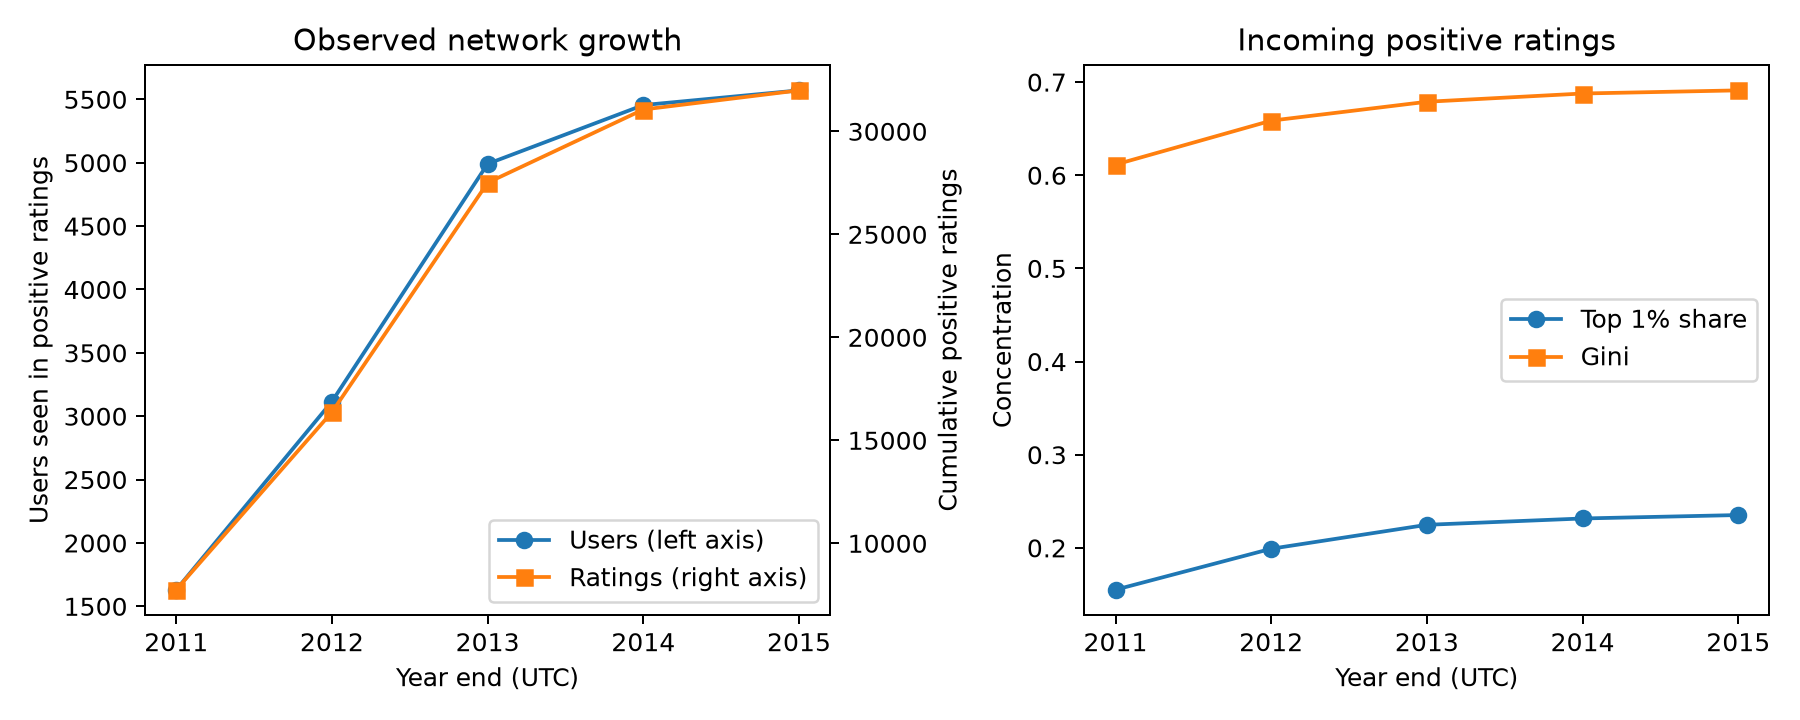

In [2]:
display(annual.round(4))
Image(filename=str(OUT / 'growth_and_concentration.png'))

### Recalculate the 2015 value from the data file

Here we do not use the saved table. We keep positive ratings from before 1 January 2016, count how many ratings each user received, and add up the top 1%.

In [3]:
ratings = pd.read_csv(ROOT / 'data' / 'soc-sign-bitcoinotc.csv.gz', header=None,
                      names=['source', 'target', 'rating', 'time'])
end_2015 = pd.Timestamp('2016-01-01', tz='UTC').timestamp()

up_to_2015 = ratings[(ratings['rating'] > 0) & (ratings['time'] < end_2015)]
users = set(up_to_2015['source']) | set(up_to_2015['target'])

received = up_to_2015['target'].value_counts().reindex(sorted(users), fill_value=0)
top_size = int(np.ceil(0.01 * len(users)))
top_share = received.sort_values(ascending=False).head(top_size).sum() / received.sum()

print('Users so far:', len(users))
print('Top 1% =', top_size, 'users')
print('Top 1% share, recalculated:', round(top_share, 4))
print('Top 1% share, saved table: ', round(annual.set_index('year_end').loc[2015, 'top_1_percent_incoming_share'], 4))

Users so far: 5571
Top 1% = 56 users
Top 1% share, recalculated: 0.2352
Top 1% share, saved table:  0.2352


## 3. Who receives the next rating?

This is how the course measures preferential attachment from data (Barabási, Section 5.6): for each new link, compare the degree of the node that got it with the other nodes it could have gone to.

Before each positive rating $u \to v$, the possible recipients are users already seen in earlier positive ratings, except $u$ itself and anyone $u$ has already rated. If $v$ is brand new, we skip that rating. We put the possible recipients in groups by how many positive ratings they had already received (0, 1, 2–3, …, 32+). If every possible recipient were equally likely, a group's expected count for that rating is its share of the possible recipients. Adding these up over all ratings gives the expected count $E_k$; the actual count is $O_k$, and

$$R_k = \frac{O_k}{E_k}.$$

$R_k = 1$ means the group was chosen as often as chance predicts. Under BA's preferential attachment, $R_k$ would rise with $k$. This comparison ignores how active or how long-standing users are; notebook 04 adds that.

,prior_positive_in_degree,observed_target_events,uniform_null_expected_events,observed_over_expected
0,0,601,341.660,1.759
1,1,3090,11200.671,0.276
2,2-3,3717,7671.863,0.484
3,4-7,4145,4133.610,1.003
4,8-15,4223,2282.943,1.850
5,16-31,4001,922.895,4.335
6,32+,7356,579.358,12.697


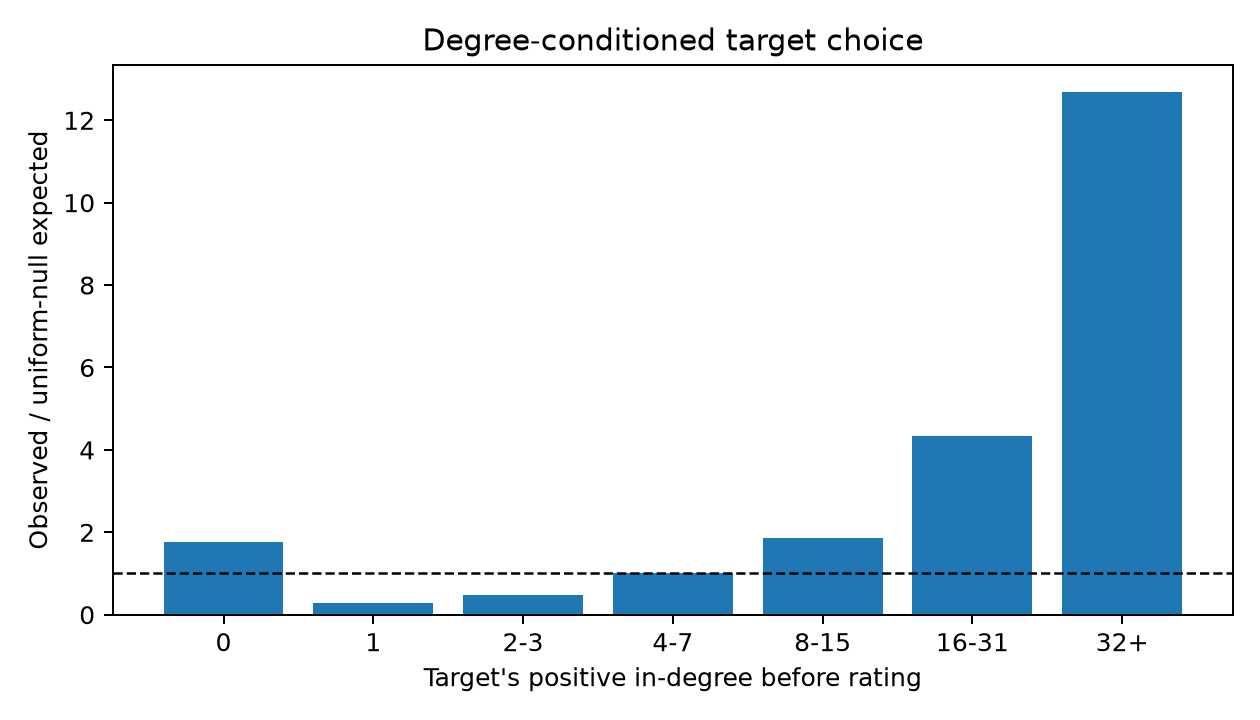

,year,prior_positive_in_degree,observed_target_events,uniform_null_expected_events,observed_over_expected
13,2011,32+,720,63.739,11.296
20,2012,32+,2107,162.001,13.006
27,2013,32+,2942,243.703,12.072
34,2014,32+,1147,86.252,13.298
41,2015,32+,419,22.636,18.510


In [4]:
display(choice.round(3))
display(Image(filename=str(OUT / 'target_choice_ratio.png')))

# the 32+ group in each full year
high = by_year[(by_year['prior_positive_in_degree'] == '32+') & by_year['year'].between(2011, 2015)]
high.round(3)

### Work through one rating

An **invented** example with six ratings. Before the last rating A → C we have seen users A, B, C, D and E. A cannot rate itself and has already rated B, so the possible recipients are C, D and E. C has received one rating before, D and E none. If all three were equally likely, the chance of picking the "one earlier rating" group is 1/3.

In [5]:
events = pd.DataFrame([
    ('A', 'B'), ('B', 'C'), ('C', 'B'),
    ('D', 'A'), ('E', 'A'), ('A', 'C'),
], columns=['source', 'target'])

before = events.iloc[:-1]           # everything before the last rating
rater, recipient = events.iloc[-1]  # the last rating: A -> C

seen = set(before['source']) | set(before['target'])
already_rated = set(before.loc[before['source'] == rater, 'target'])
possible = sorted(seen - {rater} - already_rated)

received_before = before['target'].value_counts()
candidates = pd.DataFrame({'user': possible})
candidates['ratings_received_before'] = [received_before.get(user, 0) for user in possible]
display(candidates)

expected = (candidates['ratings_received_before'] == 1).mean()
observed = 1 if received_before.get(recipient, 0) == 1 else 0
print('Expected count for the one-rating group:', round(expected, 3))
print('Observed count:', observed)
print('Observed / expected:', observed / expected)

,user,ratings_received_before
0,C,1
1,D,0
2,E,0


Expected count for the one-rating group: 0.333
Observed count: 1
Observed / expected: 3.0


For this one rating the ratio is $1/(1/3) = 3$, but one rating on its own says nothing. The script adds up the observed and expected counts over all ratings first, and only then divides the totals.

## 4. Stronger ratings only

As a check, we repeat the year-end concentration using only ratings of +5 or more.

In [6]:
display(strong.round(4))

all_positive = annual.set_index('year_end')['top_1_percent_incoming_share']
plus_five = strong.set_index('year_end')['top_1_percent_incoming_share']
print('Top 1% share, 2011 -> 2015')
print('  all positive ratings: ', round(all_positive[2011], 3), '->', round(all_positive[2015], 3))
print('  ratings of +5 or more:', round(plus_five[2011], 3), '->', round(plus_five[2015], 3))

,rating_threshold,year_end,active_positive_users,cumulative_positive_ratings,top_1_percent_incoming_share,incoming_degree_gini,top_group_size
0,5,2011,443,643,0.1633,0.5502,5
1,5,2012,850,1429,0.1659,0.6216,9
2,5,2013,1398,2451,0.1877,0.6614,14
3,5,2014,1551,2793,0.1926,0.6660,16
4,5,2015,1585,2885,0.1931,0.6694,16


Top 1% share, 2011 -> 2015
  all positive ratings:  0.155 -> 0.235
  ratings of +5 or more: 0.163 -> 0.193


## 5. Accumulated ratings vs new ratings each year

The year-end totals keep every earlier rating, so they can keep rising even if new ratings are spread more evenly. `temporal_sensitivity.py` therefore also looks at each calendar year on its own: only that year's ratings and the users in them.

,year,users_in_denominator,incoming_ratings_in_denominator,top_group_size,top_1_percent_incoming_share,incoming_degree_gini
0,2011,1618,7603,17,0.1527,0.6083
1,2012,1823,8622,19,0.1967,0.6568
2,2013,2480,11138,25,0.2096,0.6490
3,2014,916,3555,10,0.1437,0.6256
4,2015,323,929,4,0.1130,0.5728


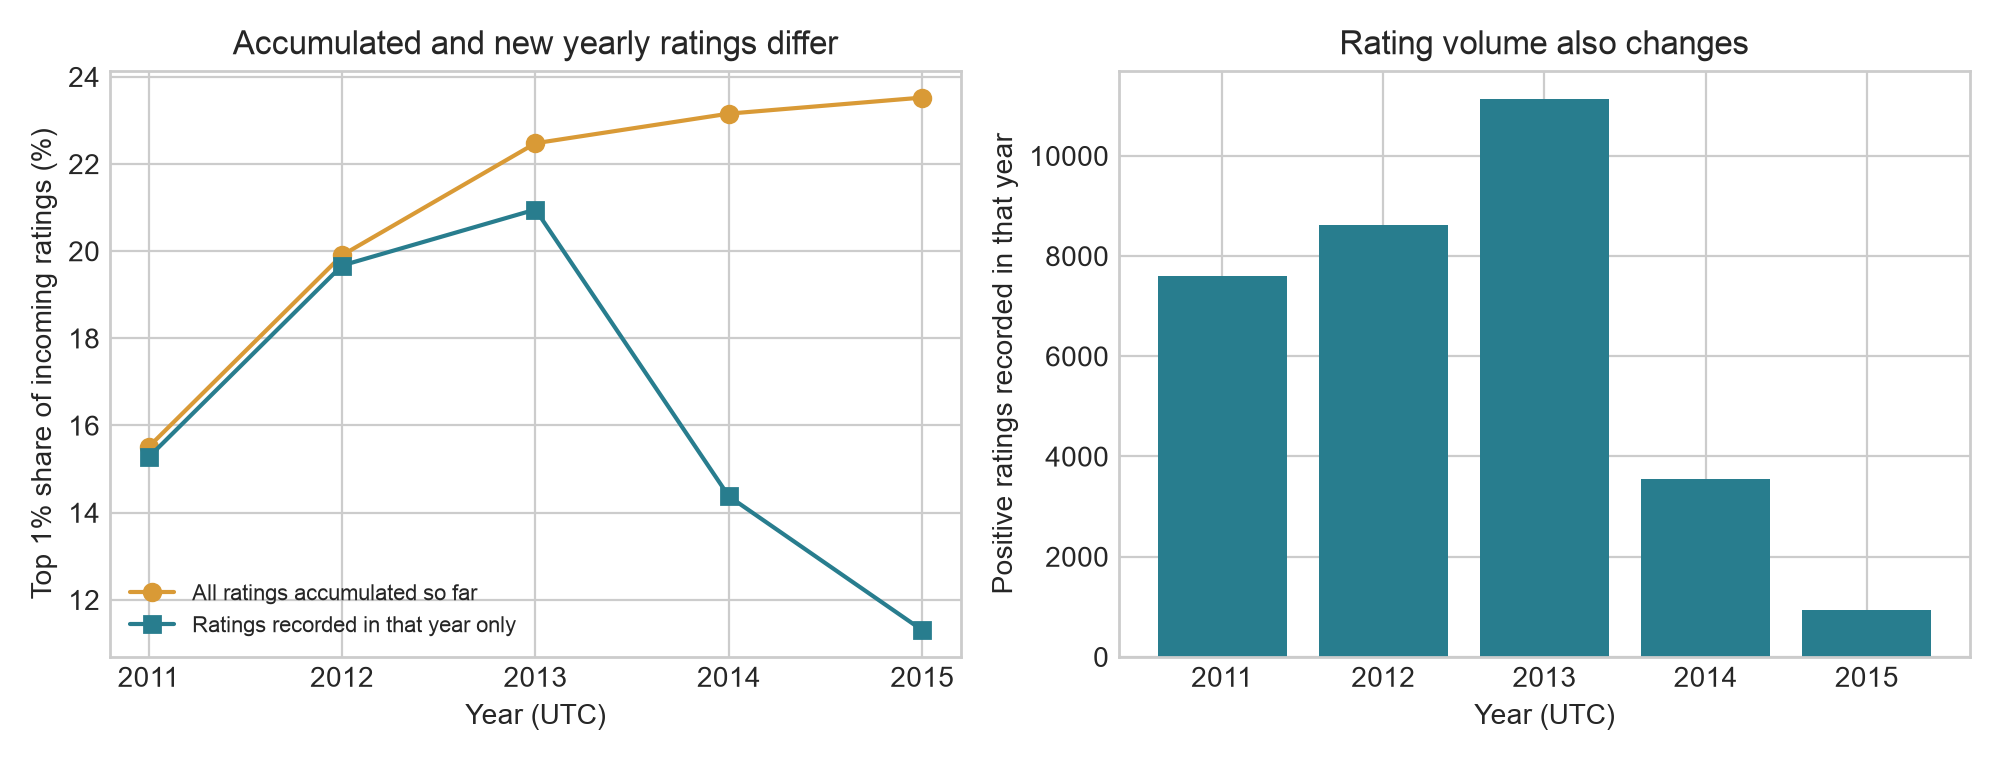

2015 only: 929 ratings among 323 users
Top 1% = 4 users, share 0.113
Saved table: 0.113


In [7]:
SENS = ROOT / 'outputs' / 'sensitivity'
annual_only = pd.read_csv(SENS / 'annual_only_concentration.csv')
fixed_cohort = pd.read_csv(SENS / 'fixed_2011_cohort_concentration.csv')
display(annual_only.round(4))
display(Image(filename=str(SENS / 'annual_vs_cumulative_concentration.png')))

# recalculate 2015 on its own from the data file
start_2015 = pd.Timestamp('2015-01-01', tz='UTC').timestamp()
in_2015 = ratings[(ratings['rating'] > 0) & (ratings['time'] >= start_2015) & (ratings['time'] < end_2015)]
users_2015 = set(in_2015['source']) | set(in_2015['target'])
received_2015 = in_2015['target'].value_counts().reindex(sorted(users_2015), fill_value=0)
top_size_2015 = int(np.ceil(0.01 * len(users_2015)))
share_2015 = received_2015.sort_values(ascending=False).head(top_size_2015).sum() / received_2015.sum()

print('2015 only:', len(in_2015), 'ratings among', len(users_2015), 'users')
print('Top 1% =', top_size_2015, 'users, share', round(share_2015, 4))
print('Saved table:', round(annual_only.set_index('year').loc[2015, 'top_1_percent_incoming_share'], 4))

The yearly share rises to 21.0% in 2013 and then falls to 11.3% in 2015. But the top 1% is 25 users in 2013 and only 4 in 2015, and the number of ratings fell from 11,138 to 929, so the raw shares are not directly comparable. The next table redraws every year to the same 743 ratings. Then 2013 gives 12.1% and 2015 gives 10.0%, with overlapping ranges, and the four largest recipients in each sample (reselected every time) hold 7.8% and 11.6%. **So the apparent fall is sensitive to the number of ratings:** the data do not show that new ratings became less concentrated. Redrawing also changes which users appear, so this does not prove that volume alone caused the fall.

In [8]:
pd.read_csv(SENS / 'annual_equal_volume_check.csv').round(4)

,year,ratings,top_1_percent_share,equal_volume_ratings,equal_volume_share_mean,equal_volume_share_low,equal_volume_share_high,fixed_recipients,fixed_recipients_share,fixed_recipients_equal_volume_mean,fixed_recipients_equal_volume_low,fixed_recipients_equal_volume_high
0,2011,7603,0.1527,743,0.0954,0.0794,0.1117,4,0.0583,0.0642,0.0498,0.0781
1,2012,8622,0.1967,743,0.1121,0.0929,0.1332,4,0.0699,0.0748,0.0592,0.0915
2,2013,11138,0.2096,743,0.1205,0.1009,0.1413,4,0.0729,0.0778,0.0619,0.0956
3,2014,3555,0.1437,743,0.0961,0.0794,0.1157,4,0.0731,0.0786,0.0646,0.0942
4,2015,929,0.1130,743,0.0996,0.0834,0.1225,4,0.1130,0.1156,0.1063,0.1252


Finally, the **fixed 2011 cohort** keeps the same 1,631 users (everyone seen by the end of 2011) in every year and counts all the positive ratings they receive later. Their top 1% share also rises, from 15.5% to 22.2%, so the rising concentration is not just caused by new users joining.

,year_end,users_in_denominator,incoming_ratings_in_denominator,top_group_size,top_1_percent_incoming_share,incoming_degree_gini,share_of_all_cumulative_ratings_received_by_cohort
0,2011,1631,7745,17,0.1551,0.6115,1.0000
1,2012,1631,10526,17,0.1881,0.6698,0.6431
2,2013,1631,12090,17,0.2143,0.6950,0.4396
3,2014,1631,12587,17,0.2196,0.7028,0.4052
4,2015,1631,12739,17,0.2218,0.7054,0.3982


Same users every year: True


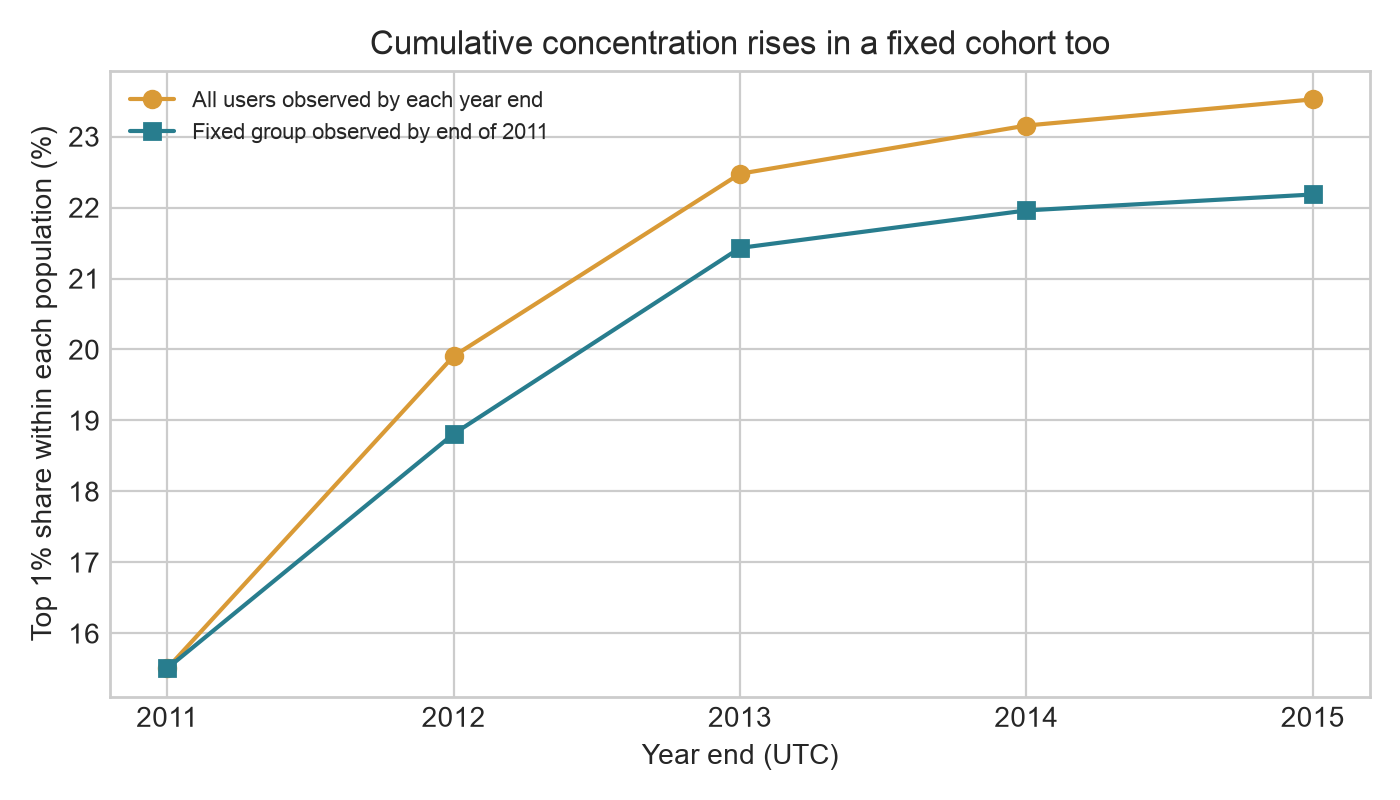

In [9]:
display(fixed_cohort.round(4))
print('Same users every year:', fixed_cohort['users_in_denominator'].nunique() == 1)
Image(filename=str(SENS / 'fixed_cohort_concentration.png'))

## References

- [SNAP Bitcoin OTC dataset and dataset paper](https://snap.stanford.edu/data/soc-sign-bitcoinotc.html)
- [Barabási, *Network Science*, Chapter 5 (measuring preferential attachment)](http://networksciencebook.com/)
- [Barabási and Albert (1999), emergence of scaling](https://doi.org/10.1126/science.286.5439.509)
- [Jeong, Néda and Barabási (2003), measuring preferential attachment](https://doi.org/10.1209/epl/i2003-00166-9)